In [3]:

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Dropout,
    GlobalAveragePooling2D,
    Dense
)
from tensorflow.keras.utils import plot_model, to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Hyperparamètres initiaux
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 0.001
RANDOM_SEED = 42

tf.keras.utils.set_random_seed(RANDOM_SEED)

print("TensorFlow version :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices("GPU"))


TensorFlow version : 2.20.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:

import os
import glob
import numpy as np

# Chercher les fichiers NPZ disponibles
npz_files = glob.glob("/kaggle/input/**/*.npz", recursive=True)

for file in npz_files:
    print(file)


/kaggle/input/datasets/elallimouad/brain-data-set/medical_dataset.npz


In [5]:

# Remplace le chemin par le chemin affiché ci-dessus
npz_path = "/kaggle/input/datasets/elallimouad/brain-data-set/medical_dataset.npz"

data = np.load(npz_path)

print("Clés disponibles :", data.files)


Clés disponibles : ['X_train', 'X_test', 'y_train', 'y_test', 'classes']


In [6]:

X_train = data["X_train"]
X_test  = data["X_test"]
y_train = data["y_train"]
y_test  = data["y_test"]

print("X_train:", X_train.shape, X_train.dtype)
print("X_test :", X_test.shape, X_test.dtype)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("Pixel min/max:", X_train.min(), X_train.max())


X_train: (5618, 224, 224, 3) float32
X_test : (1405, 224, 224, 3) float32
y_train: (5618,)
y_test : (1405,)
Pixel min/max: 0.0 1.0


In [9]:

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

print("Valeurs des pixels :", X_train.min(), "à", X_train.max())

# Vérifier la forme des images
assert X_train.ndim == 4, "X_train khaso ykoun 4D"
assert X_test.ndim == 4, "X_test khaso ykoun 4D"
assert X_train.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert X_test.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)

# Nombre de classes
num_classes = len(np.unique(np.concatenate([
    np.asarray(y_train).reshape(-1),
    np.asarray(y_test).reshape(-1)
])))

print("Nombre de classes :", num_classes)


X_train : (5618, 224, 224, 3)
X_test  : (1405, 224, 224, 3)
y_train : (5618,)
y_test  : (1405,)
Valeurs des pixels : 0.0 à 1.0
Nombre de classes : 4


In [10]:

# تحويل les labels إلى entiers
y_train_int = np.asarray(y_train).reshape(-1).astype(int)
y_test_int = np.asarray(y_test).reshape(-1).astype(int)

# تحويل les labels إلى One-Hot Encoding
y_train_cat = to_categorical(y_train_int, num_classes=num_classes)
y_test_cat = to_categorical(y_test_int, num_classes=num_classes)

print("y_train_cat :", y_train_cat.shape)
print("y_test_cat  :", y_test_cat.shape)


y_train_cat : (5618, 4)
y_test_cat  : (1405, 4)


In [11]:

model = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), padding="same", activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.30),

    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.40),

    Dense(num_classes, activation="softmax")
])

model.summary()


I0000 00:00:1792168604.756470      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792168604.760097      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modèle compilé avec succès.")


Modèle compilé avec succès.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

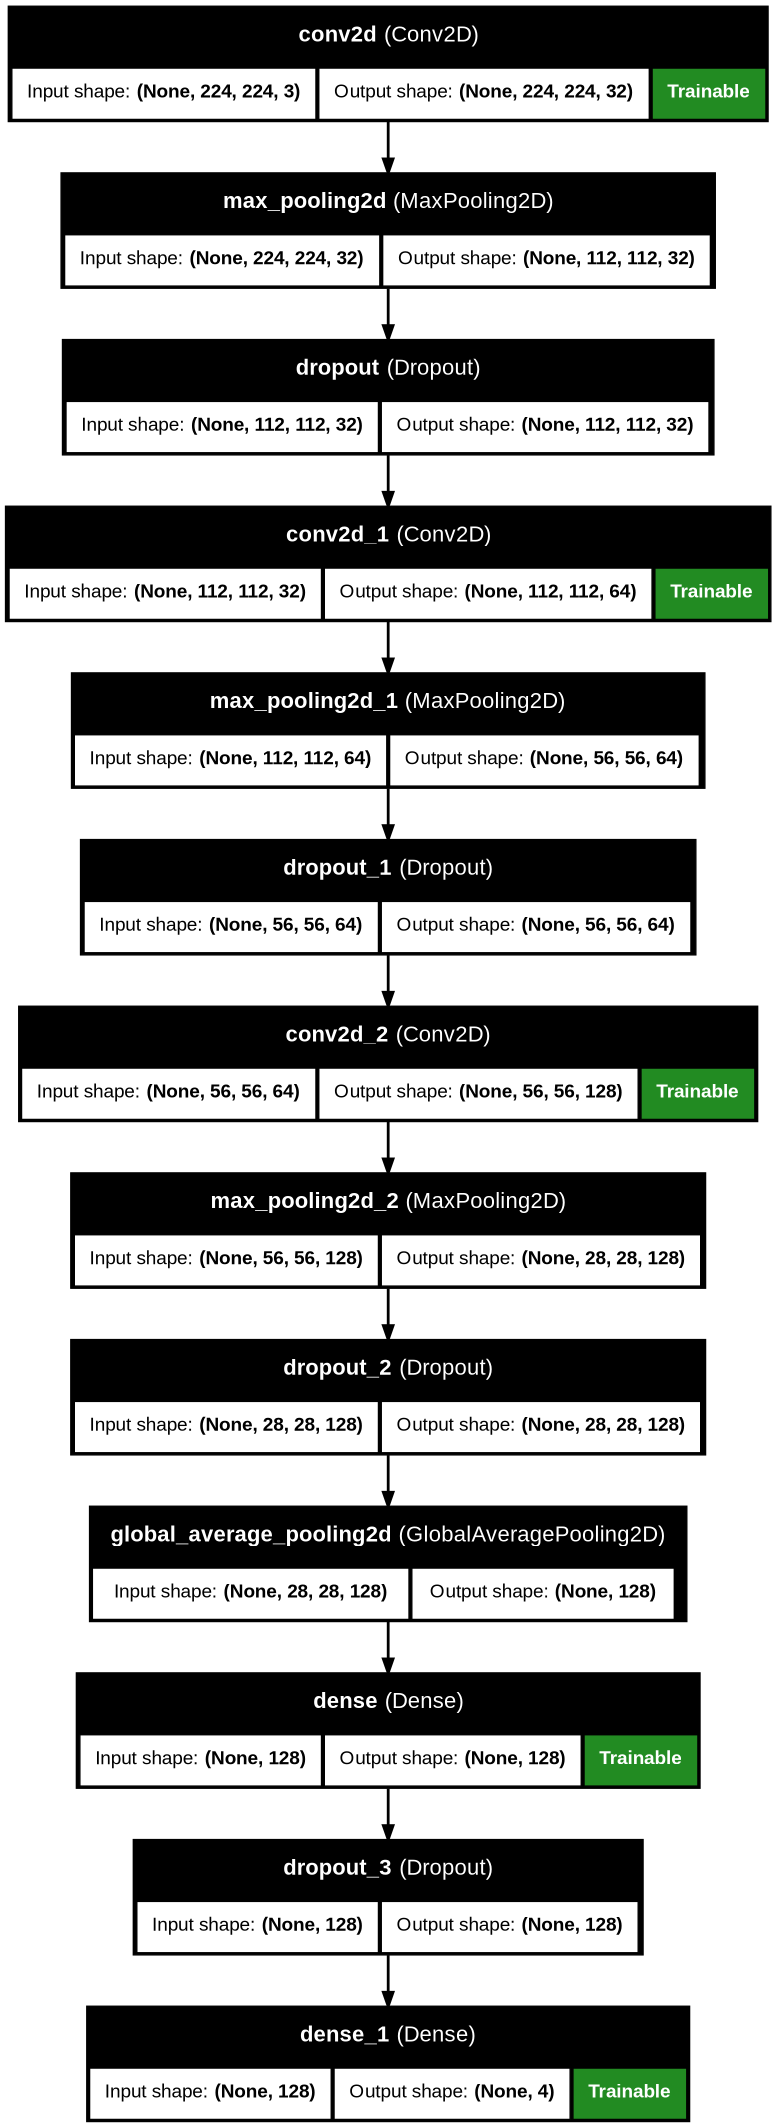

In [14]:

model.summary()

plot_model(
    model,
    to_file="/kaggle/working/cnn_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    show_trainable=True,
    dpi=100
)

from IPython.display import display, Image
display(Image("/kaggle/working/cnn_architecture.png"))


In [15]:

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        "/kaggle/working/best_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

start_time = time.time()

history = model.fit(
    X_train,
    y_train_cat,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

end_time = time.time()

training_duration = end_time - start_time

print(f"Durée d'entraînement : {training_duration:.2f} secondes")
print(f"Durée en minutes : {training_duration / 60:.2f} minutes")


Epoch 1/20
  2/141 ━━━━━━━━━━━━━━━━━━━━ 10s 76ms/step - accuracy: 0.2422 - loss: 1.3888

I0000 00:00:1792168649.797474     180 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.3177 - loss: 1.3034
Epoch 1: val_loss improved from None to 1.04973, saving model to /kaggle/working/best_cnn.keras

Epoch 1: finished saving model to /kaggle/working/best_cnn.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 25s 112ms/step - accuracy: 0.3870 - loss: 1.2184 - val_accuracy: 0.5169 - val_loss: 1.0497
Epoch 2/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.5476 - loss: 1.0356
Epoch 2: val_loss improved from 1.04973 to 0.93306, saving model to /kaggle/working/best_cnn.keras

Epoch 2: finished saving model to /kaggle/working/best_cnn.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - accuracy: 0.5710 - loss: 1.0000 - val_accuracy: 0.6112 - val_loss: 0.9331
Epoch 3/20
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.6512 - loss: 0.8932
Epoch 3: val_loss improved from 0.93306 to 0.85572, saving model to /kaggle/working/best_cnn.keras

Epoch 3: finished saving model to /kaggle/working/best_cnn.keras
141/141 ━━━━━━━━━━━━

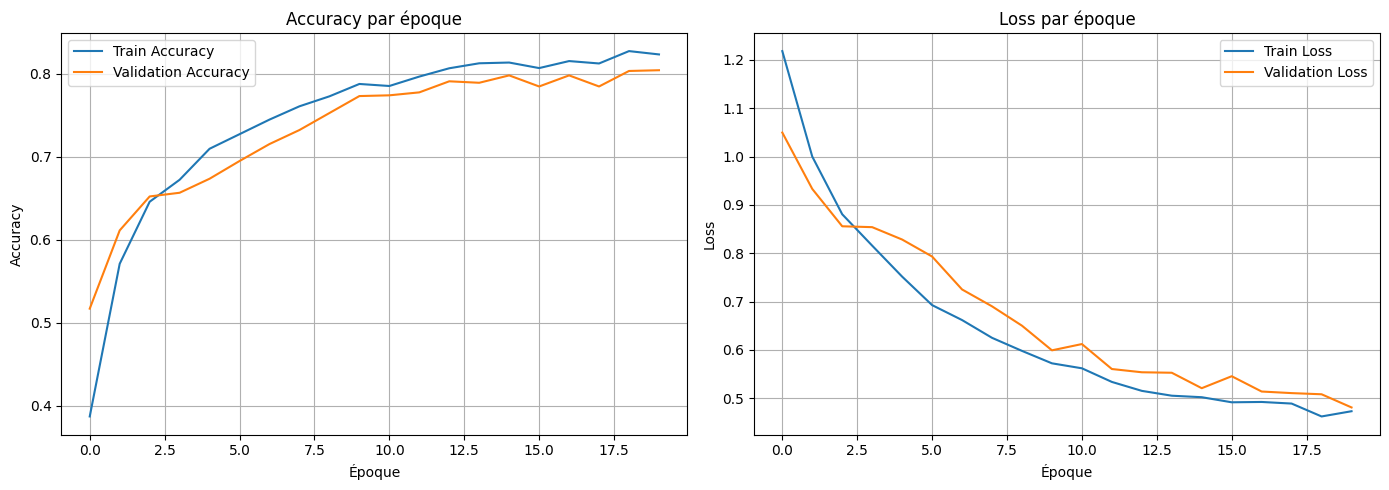

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history["accuracy"], label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Accuracy par époque")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Loss par époque")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [17]:

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_cat,
    verbose=1
)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")


44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.7964 - loss: 0.4967
Test Loss     : 0.4967
Test Accuracy : 0.7964


In [18]:

model.save("/kaggle/working/final_cnn.keras")

print("Modèle sauvegardé dans /kaggle/working/final_cnn.keras")


Modèle sauvegardé dans /kaggle/working/final_cnn.keras


44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step
              precision    recall  f1-score   support

           0     0.9171    0.6142    0.7357       324
           1     0.6257    0.7112    0.6657       329
           2     0.8836    0.9300    0.9062       400
           3     0.8295    0.9261    0.8752       352

    accuracy                         0.8050      1405
   macro avg     0.8140    0.7954    0.7957      1405
weighted avg     0.8174    0.8050    0.8028      1405



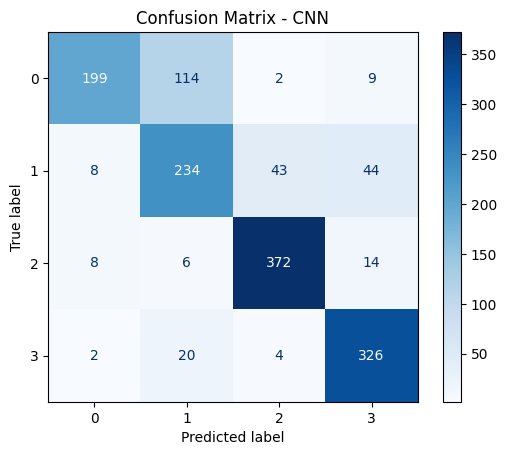

In [18]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Prédictions du modèle
y_pred_prob = model.predict(X_test, verbose=1)

# Transformer les probabilités en classes prédites
y_pred = np.argmax(y_pred_prob, axis=1)

# Transformer les labels réels en classes entières si nécessaire
y_true = np.asarray(y_test).reshape(-1).astype(int)

# Rapport de classification
print(classification_report(y_true, y_pred, digits=4))

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - CNN")
plt.show()


In [19]:

import os
import tensorflow as tf

best_model_path = "/kaggle/working/best_cnn.keras"

if os.path.exists(best_model_path):
    best_model = tf.keras.models.load_model(best_model_path)
    print("Meilleur modèle chargé :", best_model_path)
else:
    print("Fichier best_cnn.keras introuvable.")
    print("Vérifie que ModelCheckpoint était inclus dans model.fit().")


Meilleur modèle chargé : /kaggle/working/best_cnn.keras


In [22]:

from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint = ModelCheckpoint(
    filepath="/kaggle/working/best_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)



Classification Report:
              precision    recall  f1-score   support

           0     0.8289    0.6728    0.7428       324
           1     0.6395    0.6687    0.6538       329
           2     0.9002    0.9025    0.9014       400
           3     0.8060    0.9091    0.8545       352

    accuracy                         0.7964      1405
   macro avg     0.7937    0.7883    0.7881      1405
weighted avg     0.7991    0.7964    0.7951      1405



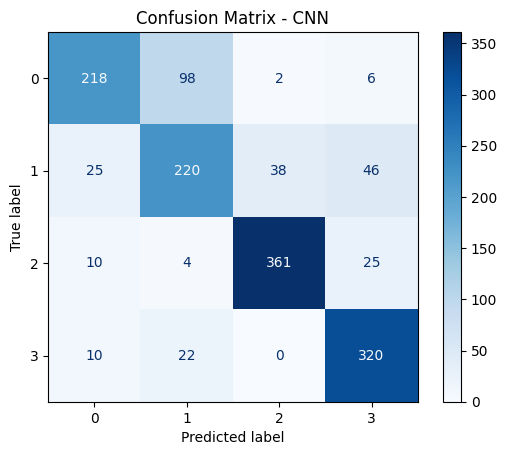

In [25]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

y_true = np.asarray(y_test).reshape(-1).astype(int)

y_prob = model_eval.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Classification Report:")
print(classification_report(y_true, y_pred, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(num_classes)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - CNN")
plt.show()


Prédictions correctes : 1119
Prédictions incorrectes : 286


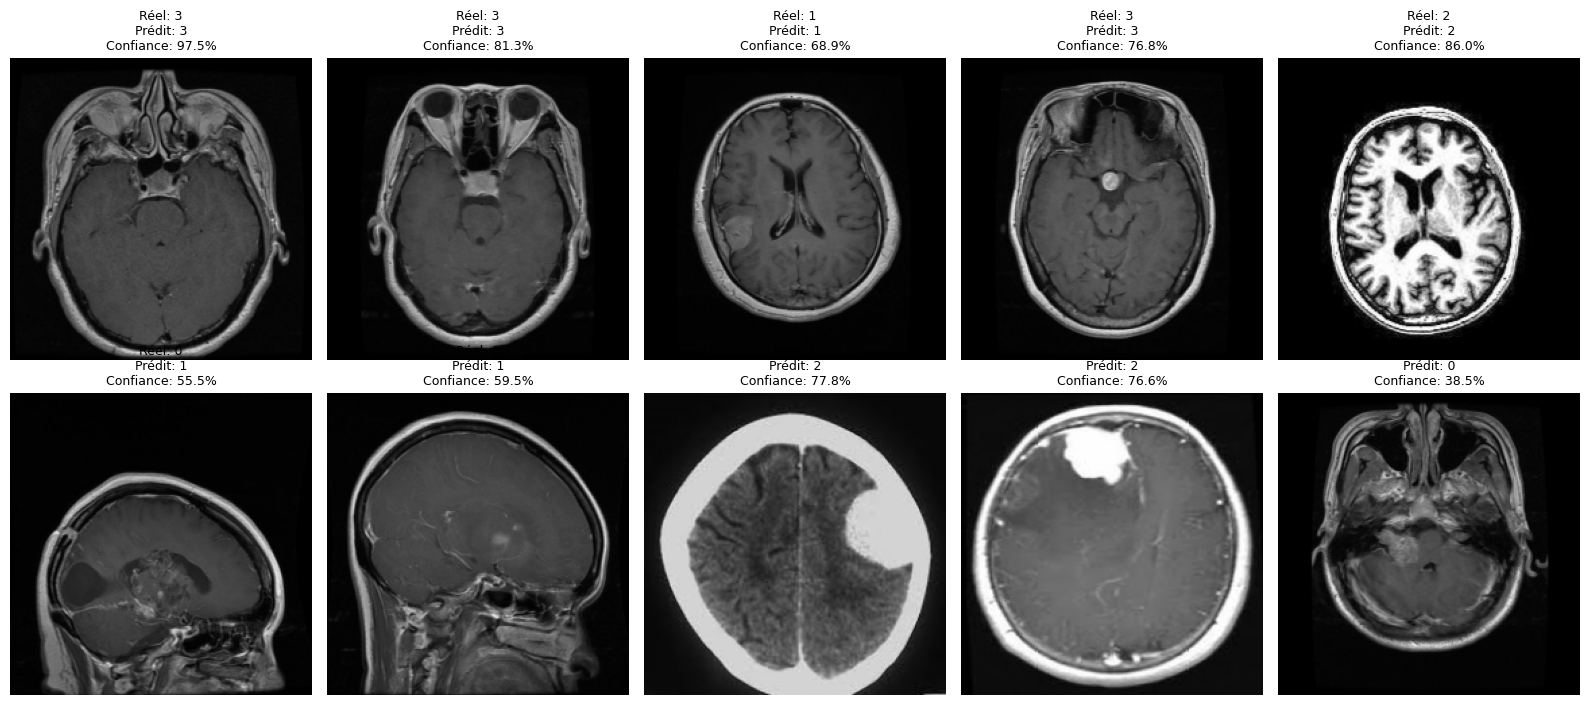

In [26]:

import numpy as np
import matplotlib.pyplot as plt

# Vraies classes et prédictions
y_true = np.asarray(y_test).reshape(-1).astype(int)
y_prob = model_eval.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Indices des prédictions correctes et incorrectes
correct_indices = np.where(y_true == y_pred)[0]
incorrect_indices = np.where(y_true != y_pred)[0]

print("Prédictions correctes :", len(correct_indices))
print("Prédictions incorrectes :", len(incorrect_indices))

# Afficher quelques exemples de chaque type
rng = np.random.default_rng(42)

n_correct = min(5, len(correct_indices))
n_incorrect = min(5, len(incorrect_indices))

selected_correct = rng.choice(
    correct_indices, size=n_correct, replace=False
) if n_correct else []

selected_incorrect = rng.choice(
    incorrect_indices, size=n_incorrect, replace=False
) if n_incorrect else []

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for row, indices, title in [
    (0, selected_correct, "Prédictions correctes"),
    (1, selected_incorrect, "Prédictions incorrectes")
]:
    for col in range(5):
        ax = axes[row, col]
        ax.axis("off")

        if col < len(indices):
            idx = indices[col]
            img = X_test[idx]

            # Afficher les images normalisées sans changer les données
            ax.imshow(np.clip(img, 0, 1))

            confidence = float(np.max(y_prob[idx])) * 100

            ax.set_title(
                f"Réel: {y_true[idx]}\n"
                f"Prédit: {y_pred[idx]}\n"
                f"Confiance: {confidence:.1f}%",
                fontsize=9
            )

    axes[row, 0].set_ylabel(title, fontsize=11)

plt.tight_layout()
plt.show()


In [27]:

final_model_path = "/kaggle/working/final_cnn.keras"

model_eval.save(final_model_path)

print("Modèle sauvegardé :", final_model_path)


Modèle sauvegardé : /kaggle/working/final_cnn.keras
